In [1]:
import pandas as pd
import numpy as np

# Load the new dataset
from google.colab import files
uploaded = files.upload()

file_name = '//content/credit_card_fraud_2026.csv'
creditcard_df = pd.read_csv(file_name)

# Display the first five transactions
creditcard_df.head()


Saving credit_card_fraud_2026.csv to credit_card_fraud_2026 (1).csv


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [2]:
print("Dataset dimensions:", creditcard_df.shape)
print("Number of transactions:", len(creditcard_df))
print("Number of columns:", len(creditcard_df.columns))

Dataset dimensions: (20000, 26)
Number of transactions: 20000
Number of columns: 26


In [3]:
# Display all column names
print("Column names:")
print(creditcard_df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
creditcard_df.info()

Column names:
['transaction_id', 'amount_usd', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt', 'merchant_risk_score', 'prior_disputes', 'is_fraud']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  object 
 3   card_type                     20000 non-null  object

In [4]:
# Check for missing values
print("Missing values per column:")
print(creditcard_df.isnull().sum())

# Count all missing values
print("\nTotal missing values:", creditcard_df.isnull().sum().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", creditcard_df.duplicated().sum())

Missing values per column:
transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


In [5]:
# Display examples of duplicate transactions
duplicate_rows = creditcard_df[creditcard_df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicate_rows))

duplicate_rows.head(10)

Total rows involved in duplicates: 0


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud


In [6]:
# Create a copy of the original dataset
creditcard_clean = creditcard_df.copy()

# Remove exact duplicate rows
creditcard_clean = creditcard_clean.drop_duplicates()

# Compare dataset dimensions
print("Original dataset:", creditcard_df.shape)
print("Cleaned dataset:", creditcard_clean.shape)

# Check remaining duplicates
print("Remaining duplicates:", creditcard_clean.duplicated().sum())

Original dataset: (20000, 26)
Cleaned dataset: (20000, 26)
Remaining duplicates: 0


In [8]:
# Count legitimate and fraudulent transactions
fraud_counts = creditcard_clean['is_fraud'].value_counts()

print("Transaction counts:")
print(fraud_counts)

# Calculate percentages
fraud_percentages = (
    creditcard_clean['is_fraud'].value_counts(normalize=True) * 100
)

print("\nTransaction percentages:")
print(fraud_percentages)


Transaction counts:
is_fraud
0    19661
1      339
Name: count, dtype: int64

Transaction percentages:
is_fraud
0    98.305
1     1.695
Name: proportion, dtype: float64


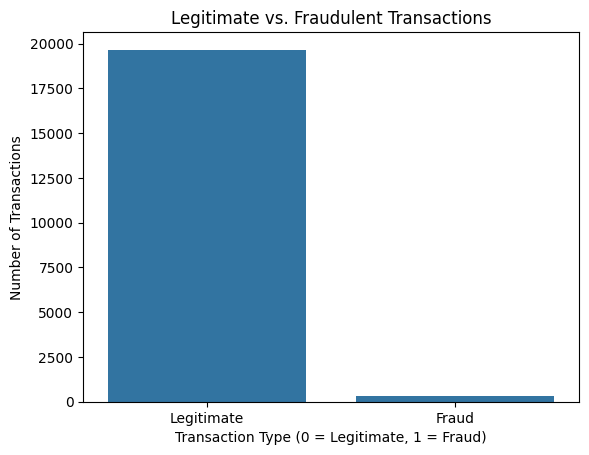

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=creditcard_clean, x='is_fraud')

plt.title('Legitimate vs. Fraudulent Transactions')
plt.xlabel('Transaction Type (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.show()


In [12]:
# Separate transaction IDs
transaction_ids = creditcard_clean['transaction_id']

# Separate features (X) and target variable (y)
X = creditcard_clean.drop(
    columns=['is_fraud', 'transaction_id']
)

y = creditcard_clean['is_fraud']

# Check dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (20000, 24)
Target shape: (20000,)

Feature columns:
['amount_usd', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt', 'merchant_risk_score', 'prior_disputes']

Target distribution:
is_fraud
0    19661
1      339
Name: count, dtype: int64


In [13]:
# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=['number']
).columns.tolist()

# Identify Boolean columns
boolean_columns = X.select_dtypes(
    include=['bool']
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)
print("\nBoolean columns:", boolean_columns)

print("\nNumber of categorical features:", len(categorical_columns))
print("Number of numerical features:", len(numerical_columns))
print("Number of Boolean features:", len(boolean_columns))


Categorical columns: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

Numerical columns: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']

Boolean columns: ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

Number of categorical features: 5
Number of numerical features: 13
Number of Boolean features: 6


In [14]:
from sklearn.model_selection import train_test_split

# First split: 60% training and 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 30% validation and 10% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

# Display dataset dimensions
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (12000, 24) (12000,)
Validation set: (6000, 24) (6000,)
Testing set: (2000, 24) (2000,)


In [16]:
# Check fraud distribution in each dataset
print("Training set:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation set:")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True) * 100)

print("\nTesting set:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)


Training set:
is_fraud
0    11797
1      203
Name: count, dtype: int64
is_fraud
0    98.308333
1     1.691667
Name: proportion, dtype: float64

Validation set:
is_fraud
0    5898
1     102
Name: count, dtype: int64
is_fraud
0    98.3
1     1.7
Name: proportion, dtype: float64

Testing set:
is_fraud
0    1966
1      34
Name: count, dtype: int64
is_fraud
0    98.3
1     1.7
Name: proportion, dtype: float64


In [17]:
print("Training transactions:", len(X_train))
print("Validation transactions:", len(X_val))
print("Testing transactions:", len(X_test))

print(
    "\nTotal transactions:",
    len(X_train) + len(X_val) + len(X_test)
)

print("Original dataset:", len(creditcard_clean))

Training transactions: 12000
Validation transactions: 6000
Testing transactions: 2000

Total transactions: 20000
Original dataset: 20000


In [18]:
# Combine features, target, and transaction IDs
train_df = pd.concat([
    transaction_ids.loc[X_train.index].rename('transaction_id'),
    X_train,
    y_train
], axis=1)

validation_df = pd.concat([
    transaction_ids.loc[X_val.index].rename('transaction_id'),
    X_val,
    y_val
], axis=1)

test_df = pd.concat([
    transaction_ids.loc[X_test.index].rename('transaction_id'),
    X_test,
    y_test
], axis=1)

# Export datasets as CSV files
train_df.to_csv('/content/train.csv', index=False)
validation_df.to_csv('/content/validation.csv', index=False)
test_df.to_csv('/content/test.csv', index=False)

print("Datasets exported successfully!")

print("\nTraining dataset:", train_df.shape)
print("Validation dataset:", validation_df.shape)
print("Testing dataset:", test_df.shape)


Datasets exported successfully!

Training dataset: (12000, 26)
Validation dataset: (6000, 26)
Testing dataset: (2000, 26)


In [19]:
from google.colab import files

files.download('/content/train.csv')
files.download('/content/validation.csv')
files.download('/content/test.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>